# Lab 9 – Learning Depth Information for Kinect Skeleton Avatars
### LSTM and GRU Deep Learning Models

**Task:** Predict the z-coordinate (depth) of 13 Kinect joints from the 2D (x, y) joint positions.

- **Input:** sequences of 13 joints × 2 dimensions (x, y) = 26 features per frame
- **Output:** 13 joints × 1 dimension (z) = 13 features per frame

**Deep Learning Steps:**
1. Load Kinect movement data (frame sequences)
2. Define LSTM / GRU deep learning networks
3. Compile (set up loss, optimizer, metrics)
4. Cross-validation: split training and testing sets (~10 test sequences per fold)
5. Train the DL models
6. Evaluate predictions (mean ± std per joint in cm)

In [37]:
import os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__}  |  device: {DEVICE}')

#  Paths 
DATA_DIR = os.path.join('..', '..', '..', 'data', 'raw', 'kinect_good_preprocessed')

#  Skeleton columns 
JOINT_NAMES = [
    'head', 'left_shoulder', 'left_elbow', 'right_shoulder', 'right_elbow',
    'left_hand', 'right_hand', 'left_hip', 'right_hip',
    'left_knee', 'right_knee', 'left_foot', 'right_foot',
]
N_JOINTS          = len(JOINT_NAMES)   # 13
N_INPUT_FEATURES  = N_JOINTS * 2       # 26  (x, y per joint)
N_OUTPUT_FEATURES = N_JOINTS           # 13  (z per joint)

X_COLS = [1, 4, 7, 10, 13, 16, 19, 22, 25, 28, 31, 34, 37]
Y_COLS = [2, 5, 8, 11, 14, 17, 20, 23, 26, 29, 32, 35, 38]
Z_COLS = [3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39]

#  Hyperparameters 
WINDOW_SIZE = 20    # frames per input window
N_FOLDS     = 18    # k = 18 → 179 / 18 ≈ 10 test sequences per fold
BATCH_SIZE  = 64
MAX_EPOCHS  = 100
PATIENCE    = 15    # early-stopping patience

PyTorch 2.12.0.dev20260408+cu128  |  device: cuda


---
## Step 1 – Load Kinect Movement Data

In [38]:
csv_files = sorted(glob.glob(os.path.join(DATA_DIR, '*.csv')))
print(f'Found {len(csv_files)} sequence files')

sequences = []
for f in csv_files:
    df = pd.read_csv(f, header=0)
    df.columns = df.columns.str.strip()
    sequences.append(df)

seq_lengths = [len(s) for s in sequences]
print(f'Lengths  min={min(seq_lengths)}  max={max(seq_lengths)}'
      f'  mean={np.mean(seq_lengths):.1f}  median={np.median(seq_lengths):.1f}')
print(f'Sample columns: {list(sequences[0].columns[:5])}...')

Found 179 sequence files
Lengths  min=48  max=315  mean=134.1  median=120.0
Sample columns: ['FrameNo', 'head_x', 'head_y', 'head_z', 'left_shoulder_x']...


In [39]:
def build_windows(seqs, window_size=WINDOW_SIZE):
    """Sliding-window samples from all sequences.

    Input  X : (window_size, 26) – x,y of 13 joints per frame
    Target y : (13,)             – z of 13 joints at the last frame of the window
    seq_id   : int               – source sequence index (used for CV splits)
    """
    X_list, y_list, sid_list = [], [], []
    for sid, df in enumerate(seqs):
        xy = np.zeros((len(df), N_INPUT_FEATURES), dtype=np.float32)
        for j in range(N_JOINTS):
            xy[:, j * 2]     = df.iloc[:, X_COLS[j]].values
            xy[:, j * 2 + 1] = df.iloc[:, Y_COLS[j]].values
        z = df.iloc[:, Z_COLS].values.astype(np.float32)
        for i in range(len(df) - window_size + 1):
            X_list.append(xy[i : i + window_size])
            y_list.append(z[i + window_size - 1])
            sid_list.append(sid)
    return (np.array(X_list), np.array(y_list), np.array(sid_list, dtype=np.int32))


X_all, y_all, seq_ids = build_windows(sequences)
unique_seq_ids = np.unique(seq_ids)

print(f'Total windows  : {X_all.shape[0]}')
print(f'Input  X shape : {X_all.shape[1:]}  (window_size × features)')
print(f'Output y shape : {y_all.shape[1:]}  (z per joint)')
print(f'z range (m)    : [{y_all.min():.4f}, {y_all.max():.4f}]')

Total windows  : 20604
Input  X shape : (20, 26)  (window_size × features)
Output y shape : (13,)  (z per joint)
z range (m)    : [-0.8143, 0.4650]


---
## Step 2 – Define Deep Learning Networks

- `nn.LSTM` / `nn.GRU` for temporal sequences (`batch_first=True`)
- Input shape: `(batch, WINDOW_SIZE=20, 26)`
- Output: last time-step hidden state → `nn.Linear(hidden_size, 13)`
- Variants: 1 or 2 stacked recurrent layers; 64 or 128 units

In [41]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=N_INPUT_FEATURES, hidden_size=64,
                 n_layers=1, output_size=N_OUTPUT_FEATURES, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size, num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)          # out: (batch, seq, hidden)
        return self.fc(out[:, -1, :])  # last time-step → (batch, 13)


class GRUModel(nn.Module):
    def __init__(self, input_size=N_INPUT_FEATURES, hidden_size=64,
                 n_layers=1, output_size=N_OUTPUT_FEATURES, dropout=0.0):
        super().__init__()
        self.gru = nn.GRU(
            input_size, hidden_size, num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(f'LSTM (1L, 64)   params: {count_params(LSTMModel(hidden_size=64,  n_layers=1)):,}')
print(f'LSTM (2L, 64)   params: {count_params(LSTMModel(hidden_size=64,  n_layers=2)):,}')
print(f'GRU  (1L, 64)   params: {count_params(GRUModel( hidden_size=64,  n_layers=1)):,}')
print(f'GRU  (2L, 64)   params: {count_params(GRUModel( hidden_size=64,  n_layers=2)):,}')
print(f'LSTM (1L, 128)  params: {count_params(LSTMModel(hidden_size=128, n_layers=1)):,}')
print(f'GRU  (1L, 128)  params: {count_params(GRUModel( hidden_size=128, n_layers=1)):,}')

LSTM (1L, 64)   params: 24,397
LSTM (2L, 64)   params: 57,677
GRU  (1L, 64)   params: 18,509
GRU  (2L, 64)   params: 43,469
LSTM (1L, 128)  params: 81,549
GRU  (1L, 128)  params: 61,581


---
## Step 3 – Set Up Loss, Optimizer, and Metrics

- **Loss:** `nn.MSELoss()` — standard regression loss
- **Metric:** MAE — interpretable; reported in cm at evaluation
- **Optimizers tested:** Adam (default), RMSprop, SGD

In [42]:
def make_optimizer(model, name='adam'):
    if name == 'adam':
        return torch.optim.Adam(model.parameters(), lr=1e-3)
    elif name == 'rmsprop':
        return torch.optim.RMSprop(model.parameters(), lr=1e-3)
    elif name == 'sgd':
        return torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)
    raise ValueError(name)


def make_loaders(X_tr, y_tr, val_frac=0.1, batch_size=BATCH_SIZE):
    """Split numpy arrays into train / val DataLoaders."""
    n_val   = max(1, int(len(X_tr) * val_frac))
    n_train = len(X_tr) - n_val

    X_t = torch.from_numpy(X_tr[:n_train])
    y_t = torch.from_numpy(y_tr[:n_train])
    X_v = torch.from_numpy(X_tr[n_train:])
    y_v = torch.from_numpy(y_tr[n_train:])

    tr_loader = DataLoader(TensorDataset(X_t, y_t),
                           batch_size=batch_size, shuffle=True)
    vl_loader = DataLoader(TensorDataset(X_v, y_v),
                           batch_size=batch_size * 2, shuffle=False)
    return tr_loader, vl_loader


criterion = nn.MSELoss()


def train_one_epoch(model, loader, optimizer):
    """Run one training epoch; return mean MSE loss."""
    model.train()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)
    return total_loss / len(loader.dataset)


def eval_loss(model, loader):
    """Return mean MSE loss on loader without gradient tracking."""
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            total_loss += criterion(model(X_batch), y_batch).item() * len(X_batch)
    return total_loss / len(loader.dataset)


def predict_np(model, X):
    """Return model predictions as a numpy array; X is a numpy array."""
    model.eval()
    loader = DataLoader(TensorDataset(torch.from_numpy(X)),
                        batch_size=BATCH_SIZE * 2, shuffle=False)
    preds = []
    with torch.no_grad():
        for (X_batch,) in loader:
            preds.append(model(X_batch.to(DEVICE)).cpu().numpy())
    return np.concatenate(preds, axis=0)


# Smoke test
_m = LSTMModel().to(DEVICE)
_x = torch.from_numpy(X_all[:4]).to(DEVICE)
print(f'Forward pass OK – output shape: {_m(_x).shape}')
del _m, _x

Forward pass OK – output shape: torch.Size([4, 13])


---
## Steps 4, 5, 6 – Cross-Validation, Training, and Evaluation

- **k-fold CV** (k = 18) with splits at the *sequence* level (no data leakage)
- **Training loop:** MSE loss, backprop, optimizer step each batch
- **Early stopping:** monitor val loss, patience = 15 epochs
- **Evaluation:** per-joint MAE averaged across folds, in **cm**

In [6]:
def run_cv(model_cls, model_kwargs, optimizer_name='adam',
           n_folds=N_FOLDS, max_epochs=MAX_EPOCHS,
           patience=PATIENCE, label=''):
    """k-fold CV with per-fold standardization on X (fitted on train only).
    Returns all_mae (n_folds, 13) and train-history list.
    """
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    all_mae, histories = [], []

    for fold, (tr_idx, te_idx) in enumerate(kf.split(unique_seq_ids)):
        tr_seqs = unique_seq_ids[tr_idx]
        te_seqs = unique_seq_ids[te_idx]
        tr_mask = np.isin(seq_ids, tr_seqs)
        te_mask = np.isin(seq_ids, te_seqs)

        X_tr, y_tr = X_all[tr_mask], y_all[tr_mask]
        X_te, y_te = X_all[te_mask], y_all[te_mask]

        # ── Standardize X: fit on train windows only ───────────────────────
        # Reshape to 2D, fit, reshape back to (n, window, features)
        n_tr, n_te = len(X_tr), len(X_te)
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr.reshape(-1, N_INPUT_FEATURES)).reshape(n_tr, WINDOW_SIZE, N_INPUT_FEATURES).astype('float32')
        X_te = scaler.transform(    X_te.reshape(-1, N_INPUT_FEATURES)).reshape(n_te, WINDOW_SIZE, N_INPUT_FEATURES).astype('float32')

        # Step 2+3: fresh model & optimizer each fold
        model = model_cls(**model_kwargs).to(DEVICE)
        optimizer = make_optimizer(model, optimizer_name)
        tr_loader, vl_loader = make_loaders(X_tr, y_tr)

        # Step 5: training loop with early stopping
        best_val, wait = float('inf'), 0
        best_state = None
        hist_train, hist_val = [], []

        for epoch in range(max_epochs):
            tr_loss = train_one_epoch(model, tr_loader, optimizer)
            vl_loss = eval_loss(model, vl_loader)
            hist_train.append(tr_loss)
            hist_val.append(vl_loss)

            if vl_loss < best_val - 1e-7:
                best_val = vl_loss
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break

        model.load_state_dict(best_state)
        histories.append({'train': hist_train, 'val': hist_val})

        # Step 6: evaluate on held-out sequences
        y_pred = predict_np(model, X_te)
        mae_j  = np.mean(np.abs(y_pred - y_te), axis=0)   # (13,)
        all_mae.append(mae_j)

        ep = len(hist_train)
        print(f'  [{label}] fold {fold+1:2d}/{n_folds}  '
              f'epochs={ep:3d}  test_MAE={np.mean(mae_j)*100:.3f} cm')

    return np.array(all_mae), histories


def print_results(all_mae, label=''):
    m = np.mean(all_mae, axis=0) * 100
    s = np.std(all_mae,  axis=0) * 100
    print(f'\n── {label} ──────────────────────────────')
    for j, name in enumerate(JOINT_NAMES):
        print(f'  {name:20s}  mean={m[j]:.3f} cm  std={s[j]:.3f} cm')
    print(f'  {"Average distance":20s}  {m.mean():.3f} cm')

---
## Model Variants

| # | Type | Layers | Units | Optimizer |
|---|------|--------|-------|-----------|
| 1 | LSTM | 1      | 64    | Adam      |
| 2 | LSTM | 2      | 64    | Adam      |
| 3 | GRU  | 1      | 64    | Adam      |
| 4 | GRU  | 2      | 64    | Adam      |
| 5 | LSTM | 1      | 128   | Adam      |
| 6 | GRU  | 1      | 128   | Adam      |
| 7 | LSTM | 1      | 64    | RMSprop   |
| 8 | LSTM | 1      | 64    | SGD       |

In [ ]:
# Variant 1: LSTM-1L-64-Adam
print('Running LSTM-1L-64-Adam ...')
mae_lstm_1l_64_adam, hist_lstm_1l_64_adam = run_cv(
    model_cls=LSTMModel, model_kwargs=dict(hidden_size=64, n_layers=1),
    optimizer_name='adam', label='LSTM-1L-64-Adam',
)
print_results(mae_lstm_1l_64_adam, 'LSTM-1L-64-Adam')

Running LSTM-1L-64-Adam ...
  [LSTM-1L-64-Adam] fold  1/18  epochs= 16  test_MAE=4.286 cm
  [LSTM-1L-64-Adam] fold  2/18  epochs= 19  test_MAE=2.998 cm
  [LSTM-1L-64-Adam] fold  3/18  epochs= 24  test_MAE=2.508 cm
  [LSTM-1L-64-Adam] fold  4/18  epochs= 39  test_MAE=2.857 cm
  [LSTM-1L-64-Adam] fold  5/18  epochs= 17  test_MAE=5.458 cm
  [LSTM-1L-64-Adam] fold  6/18  epochs= 17  test_MAE=4.208 cm
  [LSTM-1L-64-Adam] fold  7/18  epochs= 23  test_MAE=4.276 cm
  [LSTM-1L-64-Adam] fold  8/18  epochs= 16  test_MAE=4.638 cm
  [LSTM-1L-64-Adam] fold  9/18  epochs= 17  test_MAE=4.364 cm
  [LSTM-1L-64-Adam] fold 10/18  epochs= 16  test_MAE=4.147 cm
  [LSTM-1L-64-Adam] fold 11/18  epochs= 45  test_MAE=3.960 cm
  [LSTM-1L-64-Adam] fold 12/18  epochs= 22  test_MAE=4.179 cm
  [LSTM-1L-64-Adam] fold 13/18  epochs= 17  test_MAE=4.461 cm
  [LSTM-1L-64-Adam] fold 14/18  epochs= 22  test_MAE=5.530 cm
  [LSTM-1L-64-Adam] fold 15/18  epochs= 17  test_MAE=3.009 cm
  [LSTM-1L-64-Adam] fold 16/18  epochs= 17

In [ ]:
# Variant 2: LSTM-2L-64-Adam
print('Running LSTM-2L-64-Adam ...')
mae_lstm_2l_64_adam, hist_lstm_2l_64_adam = run_cv(
    model_cls=LSTMModel, model_kwargs=dict(hidden_size=64, n_layers=2),
    optimizer_name='adam', label='LSTM-2L-64-Adam',
)
print_results(mae_lstm_2l_64_adam, 'LSTM-2L-64-Adam')

Running LSTM-2L-64-Adam ...
  [LSTM-2L-64-Adam] fold  1/18  epochs= 19  test_MAE=4.076 cm
  [LSTM-2L-64-Adam] fold  2/18  epochs= 20  test_MAE=2.748 cm
  [LSTM-2L-64-Adam] fold  3/18  epochs= 34  test_MAE=2.652 cm
  [LSTM-2L-64-Adam] fold  4/18  epochs= 16  test_MAE=3.693 cm
  [LSTM-2L-64-Adam] fold  5/18  epochs= 16  test_MAE=4.751 cm
  [LSTM-2L-64-Adam] fold  6/18  epochs= 65  test_MAE=4.408 cm
  [LSTM-2L-64-Adam] fold  7/18  epochs= 29  test_MAE=4.160 cm
  [LSTM-2L-64-Adam] fold  8/18  epochs= 16  test_MAE=4.208 cm
  [LSTM-2L-64-Adam] fold  9/18  epochs= 17  test_MAE=3.905 cm
  [LSTM-2L-64-Adam] fold 10/18  epochs= 18  test_MAE=3.835 cm
  [LSTM-2L-64-Adam] fold 11/18  epochs= 18  test_MAE=4.223 cm
  [LSTM-2L-64-Adam] fold 12/18  epochs= 18  test_MAE=3.846 cm
  [LSTM-2L-64-Adam] fold 13/18  epochs= 22  test_MAE=4.131 cm
  [LSTM-2L-64-Adam] fold 14/18  epochs= 26  test_MAE=6.467 cm
  [LSTM-2L-64-Adam] fold 15/18  epochs= 16  test_MAE=3.213 cm
  [LSTM-2L-64-Adam] fold 16/18  epochs= 17

In [ ]:
# Variant 3: GRU-1L-64-Adam
print('Running GRU-1L-64-Adam ...')
mae_gru_1l_64_adam, hist_gru_1l_64_adam = run_cv(
    model_cls=GRUModel, model_kwargs=dict(hidden_size=64, n_layers=1),
    optimizer_name='adam', label='GRU-1L-64-Adam',
)
print_results(mae_gru_1l_64_adam, 'GRU-1L-64-Adam')

Running GRU-1L-64-Adam ...
  [GRU-1L-64-Adam] fold  1/18  epochs= 17  test_MAE=4.157 cm
  [GRU-1L-64-Adam] fold  2/18  epochs= 43  test_MAE=3.162 cm
  [GRU-1L-64-Adam] fold  3/18  epochs= 21  test_MAE=3.148 cm
  [GRU-1L-64-Adam] fold  4/18  epochs= 21  test_MAE=3.054 cm
  [GRU-1L-64-Adam] fold  5/18  epochs= 18  test_MAE=5.606 cm
  [GRU-1L-64-Adam] fold  6/18  epochs= 18  test_MAE=3.940 cm
  [GRU-1L-64-Adam] fold  7/18  epochs= 20  test_MAE=4.784 cm
  [GRU-1L-64-Adam] fold  8/18  epochs= 24  test_MAE=3.839 cm
  [GRU-1L-64-Adam] fold  9/18  epochs= 33  test_MAE=4.106 cm
  [GRU-1L-64-Adam] fold 10/18  epochs= 44  test_MAE=3.359 cm
  [GRU-1L-64-Adam] fold 11/18  epochs= 56  test_MAE=4.155 cm
  [GRU-1L-64-Adam] fold 12/18  epochs= 94  test_MAE=4.481 cm
  [GRU-1L-64-Adam] fold 13/18  epochs= 20  test_MAE=4.566 cm
  [GRU-1L-64-Adam] fold 14/18  epochs= 32  test_MAE=6.698 cm
  [GRU-1L-64-Adam] fold 15/18  epochs= 21  test_MAE=2.672 cm
  [GRU-1L-64-Adam] fold 16/18  epochs= 18  test_MAE=5.182 

In [ ]:
# Variant 4: GRU-2L-64-Adam
print('Running GRU-2L-64-Adam ...')
mae_gru_2l_64_adam, hist_gru_2l_64_adam = run_cv(
    model_cls=GRUModel, model_kwargs=dict(hidden_size=64, n_layers=2),
    optimizer_name='adam', label='GRU-2L-64-Adam',
)
print_results(mae_gru_2l_64_adam, 'GRU-2L-64-Adam')

Running GRU-2L-64-Adam ...
  [GRU-2L-64-Adam] fold  1/18  epochs= 19  test_MAE=3.563 cm
  [GRU-2L-64-Adam] fold  2/18  epochs= 19  test_MAE=3.192 cm
  [GRU-2L-64-Adam] fold  3/18  epochs= 19  test_MAE=2.838 cm
  [GRU-2L-64-Adam] fold  4/18  epochs= 20  test_MAE=3.222 cm
  [GRU-2L-64-Adam] fold  5/18  epochs= 22  test_MAE=5.426 cm
  [GRU-2L-64-Adam] fold  6/18  epochs= 19  test_MAE=4.146 cm
  [GRU-2L-64-Adam] fold  7/18  epochs= 47  test_MAE=4.567 cm
  [GRU-2L-64-Adam] fold  8/18  epochs= 70  test_MAE=3.324 cm
  [GRU-2L-64-Adam] fold  9/18  epochs= 21  test_MAE=4.275 cm
  [GRU-2L-64-Adam] fold 10/18  epochs= 19  test_MAE=3.534 cm
  [GRU-2L-64-Adam] fold 11/18  epochs= 22  test_MAE=4.081 cm
  [GRU-2L-64-Adam] fold 12/18  epochs= 30  test_MAE=3.990 cm
  [GRU-2L-64-Adam] fold 13/18  epochs= 37  test_MAE=4.079 cm
  [GRU-2L-64-Adam] fold 14/18  epochs= 32  test_MAE=6.386 cm
  [GRU-2L-64-Adam] fold 15/18  epochs= 18  test_MAE=2.866 cm
  [GRU-2L-64-Adam] fold 16/18  epochs= 18  test_MAE=4.578 

In [ ]:
# Variant 5: LSTM-1L-128-Adam
print('Running LSTM-1L-128-Adam ...')
mae_lstm_1l_128_adam, hist_lstm_1l_128_adam = run_cv(
    model_cls=LSTMModel, model_kwargs=dict(hidden_size=128, n_layers=1),
    optimizer_name='adam', label='LSTM-1L-128-Adam',
)
print_results(mae_lstm_1l_128_adam, 'LSTM-1L-128-Adam')

Running LSTM-1L-128-Adam ...
  [LSTM-1L-128-Adam] fold  1/18  epochs= 32  test_MAE=3.809 cm
  [LSTM-1L-128-Adam] fold  2/18  epochs= 57  test_MAE=3.413 cm
  [LSTM-1L-128-Adam] fold  3/18  epochs= 16  test_MAE=2.722 cm
  [LSTM-1L-128-Adam] fold  4/18  epochs= 17  test_MAE=3.355 cm
  [LSTM-1L-128-Adam] fold  5/18  epochs= 18  test_MAE=4.837 cm
  [LSTM-1L-128-Adam] fold  6/18  epochs= 41  test_MAE=4.100 cm
  [LSTM-1L-128-Adam] fold  7/18  epochs= 18  test_MAE=5.126 cm
  [LSTM-1L-128-Adam] fold  8/18  epochs= 17  test_MAE=3.756 cm
  [LSTM-1L-128-Adam] fold  9/18  epochs= 23  test_MAE=3.821 cm
  [LSTM-1L-128-Adam] fold 10/18  epochs= 16  test_MAE=3.865 cm
  [LSTM-1L-128-Adam] fold 11/18  epochs= 19  test_MAE=4.270 cm
  [LSTM-1L-128-Adam] fold 12/18  epochs=100  test_MAE=4.014 cm
  [LSTM-1L-128-Adam] fold 13/18  epochs= 27  test_MAE=4.022 cm
  [LSTM-1L-128-Adam] fold 14/18  epochs= 18  test_MAE=5.818 cm
  [LSTM-1L-128-Adam] fold 15/18  epochs= 19  test_MAE=2.808 cm
  [LSTM-1L-128-Adam] fold 

In [ ]:
# Variant 6: GRU-1L-128-Adam
print('Running GRU-1L-128-Adam ...')
mae_gru_1l_128_adam, hist_gru_1l_128_adam = run_cv(
    model_cls=GRUModel, model_kwargs=dict(hidden_size=128, n_layers=1),
    optimizer_name='adam', label='GRU-1L-128-Adam',
)
print_results(mae_gru_1l_128_adam, 'GRU-1L-128-Adam')

Running GRU-1L-128-Adam ...
  [GRU-1L-128-Adam] fold  1/18  epochs= 20  test_MAE=3.450 cm
  [GRU-1L-128-Adam] fold  2/18  epochs= 18  test_MAE=3.183 cm
  [GRU-1L-128-Adam] fold  3/18  epochs= 17  test_MAE=2.752 cm
  [GRU-1L-128-Adam] fold  4/18  epochs= 20  test_MAE=3.148 cm
  [GRU-1L-128-Adam] fold  5/18  epochs= 20  test_MAE=5.566 cm
  [GRU-1L-128-Adam] fold  6/18  epochs= 54  test_MAE=3.942 cm
  [GRU-1L-128-Adam] fold  7/18  epochs= 17  test_MAE=5.376 cm
  [GRU-1L-128-Adam] fold  8/18  epochs= 16  test_MAE=4.570 cm
  [GRU-1L-128-Adam] fold  9/18  epochs= 31  test_MAE=3.591 cm
  [GRU-1L-128-Adam] fold 10/18  epochs= 44  test_MAE=3.256 cm
  [GRU-1L-128-Adam] fold 11/18  epochs= 18  test_MAE=4.164 cm
  [GRU-1L-128-Adam] fold 12/18  epochs= 21  test_MAE=4.173 cm
  [GRU-1L-128-Adam] fold 13/18  epochs= 20  test_MAE=4.628 cm
  [GRU-1L-128-Adam] fold 14/18  epochs= 23  test_MAE=6.028 cm
  [GRU-1L-128-Adam] fold 15/18  epochs= 17  test_MAE=2.945 cm
  [GRU-1L-128-Adam] fold 16/18  epochs= 16

In [ ]:
# Variant 7: LSTM-1L-64-RMSprop
print('Running LSTM-1L-64-RMSprop ...')
mae_lstm_1l_64_rmsprop, hist_lstm_1l_64_rmsprop = run_cv(
    model_cls=LSTMModel, model_kwargs=dict(hidden_size=64, n_layers=1),
    optimizer_name='rmsprop', label='LSTM-1L-64-RMSprop',
)
print_results(mae_lstm_1l_64_rmsprop, 'LSTM-1L-64-RMSprop')

Running LSTM-1L-64-RMSprop ...
  [LSTM-1L-64-RMSprop] fold  1/18  epochs= 17  test_MAE=4.031 cm
  [LSTM-1L-64-RMSprop] fold  2/18  epochs= 27  test_MAE=2.776 cm
  [LSTM-1L-64-RMSprop] fold  3/18  epochs= 16  test_MAE=3.416 cm
  [LSTM-1L-64-RMSprop] fold  4/18  epochs= 24  test_MAE=3.041 cm
  [LSTM-1L-64-RMSprop] fold  5/18  epochs= 18  test_MAE=5.455 cm
  [LSTM-1L-64-RMSprop] fold  6/18  epochs= 21  test_MAE=3.955 cm
  [LSTM-1L-64-RMSprop] fold  7/18  epochs= 29  test_MAE=4.600 cm
  [LSTM-1L-64-RMSprop] fold  8/18  epochs= 32  test_MAE=3.970 cm
  [LSTM-1L-64-RMSprop] fold  9/18  epochs= 30  test_MAE=4.007 cm
  [LSTM-1L-64-RMSprop] fold 10/18  epochs= 23  test_MAE=3.508 cm
  [LSTM-1L-64-RMSprop] fold 11/18  epochs= 33  test_MAE=4.776 cm
  [LSTM-1L-64-RMSprop] fold 12/18  epochs= 26  test_MAE=3.873 cm
  [LSTM-1L-64-RMSprop] fold 13/18  epochs= 48  test_MAE=4.040 cm
  [LSTM-1L-64-RMSprop] fold 14/18  epochs= 20  test_MAE=5.295 cm
  [LSTM-1L-64-RMSprop] fold 15/18  epochs= 23  test_MAE=3.0

In [ ]:
# Variant 8: LSTM-1L-64-SGD
print('Running LSTM-1L-64-SGD ...')
mae_lstm_1l_64_sgd, hist_lstm_1l_64_sgd = run_cv(
    model_cls=LSTMModel, model_kwargs=dict(hidden_size=64, n_layers=1),
    optimizer_name='sgd', label='LSTM-1L-64-SGD',
)
print_results(mae_lstm_1l_64_sgd, 'LSTM-1L-64-SGD')

Running LSTM-1L-64-SGD ...
  [LSTM-1L-64-SGD] fold  1/18  epochs= 42  test_MAE=4.572 cm
  [LSTM-1L-64-SGD] fold  2/18  epochs= 83  test_MAE=3.278 cm
  [LSTM-1L-64-SGD] fold  3/18  epochs= 52  test_MAE=3.267 cm
  [LSTM-1L-64-SGD] fold  4/18  epochs= 70  test_MAE=3.769 cm
  [LSTM-1L-64-SGD] fold  5/18  epochs= 30  test_MAE=6.540 cm
  [LSTM-1L-64-SGD] fold  6/18  epochs= 22  test_MAE=4.484 cm
  [LSTM-1L-64-SGD] fold  7/18  epochs= 29  test_MAE=4.978 cm
  [LSTM-1L-64-SGD] fold  8/18  epochs= 39  test_MAE=5.053 cm
  [LSTM-1L-64-SGD] fold  9/18  epochs= 84  test_MAE=4.354 cm
  [LSTM-1L-64-SGD] fold 10/18  epochs= 73  test_MAE=4.127 cm
  [LSTM-1L-64-SGD] fold 11/18  epochs= 27  test_MAE=5.480 cm
  [LSTM-1L-64-SGD] fold 12/18  epochs=100  test_MAE=4.394 cm
  [LSTM-1L-64-SGD] fold 13/18  epochs= 60  test_MAE=5.095 cm
  [LSTM-1L-64-SGD] fold 14/18  epochs= 29  test_MAE=6.307 cm
  [LSTM-1L-64-SGD] fold 15/18  epochs= 25  test_MAE=3.816 cm
  [LSTM-1L-64-SGD] fold 16/18  epochs= 17  test_MAE=6.608 

---
## Comparison Summary

In [15]:
variant_results = [
    ('LSTM-1L-64-Adam',    mae_lstm_1l_64_adam),
    ('LSTM-2L-64-Adam',    mae_lstm_2l_64_adam),
    ('GRU-1L-64-Adam',     mae_gru_1l_64_adam),
    ('GRU-2L-64-Adam',     mae_gru_2l_64_adam),
    ('LSTM-1L-128-Adam',   mae_lstm_1l_128_adam),
    ('GRU-1L-128-Adam',    mae_gru_1l_128_adam),
    ('LSTM-1L-64-RMSprop', mae_lstm_1l_64_rmsprop),
    ('LSTM-1L-64-SGD',     mae_lstm_1l_64_sgd),
]

rows = []
for lbl, arr in variant_results:
    rows.append({'Variant': lbl,
                 'Avg MAE (cm)':  round(np.mean(arr) * 100, 3),
                 'Fold std (cm)': round(np.std(np.mean(arr, axis=1)) * 100, 3)})

summary_df = pd.DataFrame(rows).sort_values('Avg MAE (cm)')
print(summary_df.to_string(index=False))

best_label = summary_df.iloc[0]['Variant']
print(f'\nChampion: {best_label}  ({summary_df.iloc[0]["Avg MAE (cm)"]:.3f} cm)')

           Variant  Avg MAE (cm)  Fold std (cm)
LSTM-1L-64-RMSprop         3.896          0.762
    GRU-2L-64-Adam         3.921          0.890
  LSTM-1L-128-Adam         3.937          0.800
   LSTM-2L-64-Adam         3.982          0.842
   LSTM-1L-64-Adam         4.003          0.884
   GRU-1L-128-Adam         4.013          1.007
    GRU-1L-64-Adam         4.080          1.000
    LSTM-1L-64-SGD         4.658          1.010

Champion: LSTM-1L-64-RMSprop  (3.896 cm)


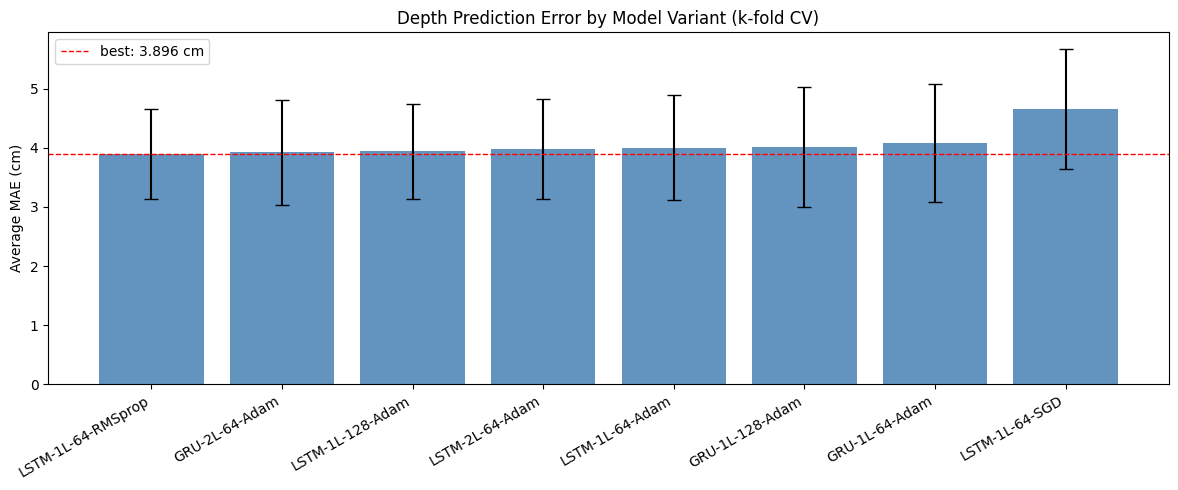

In [16]:
labels_plot = summary_df['Variant'].values
means_plot  = summary_df['Avg MAE (cm)'].values
stds_plot   = summary_df['Fold std (cm)'].values

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(labels_plot)), means_plot, yerr=stds_plot, capsize=5,
       color='steelblue', alpha=0.85)
ax.set_xticks(range(len(labels_plot)))
ax.set_xticklabels(labels_plot, rotation=30, ha='right')
ax.set_ylabel('Average MAE (cm)')
ax.set_title('Depth Prediction Error by Model Variant (k-fold CV)')
ax.axhline(means_plot.min(), color='red', linestyle='--', linewidth=1,
           label=f'best: {means_plot.min():.3f} cm')
ax.legend()
plt.tight_layout()
plt.show()

---
## Training Curve for Champion Model

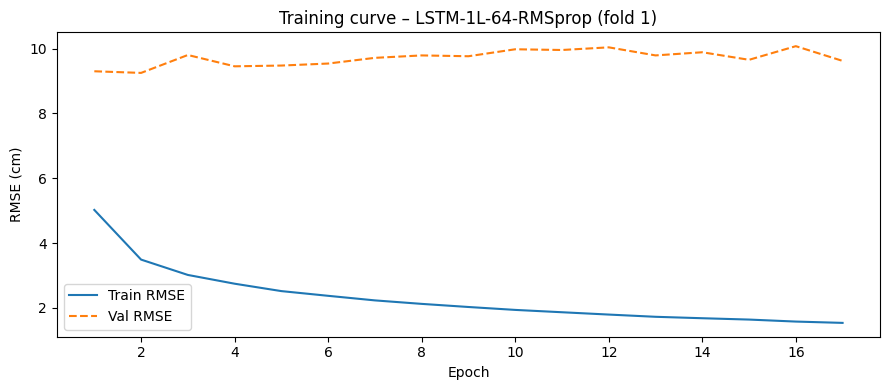

In [17]:
hist_map = {
    'LSTM-1L-64-Adam':    hist_lstm_1l_64_adam,
    'LSTM-2L-64-Adam':    hist_lstm_2l_64_adam,
    'GRU-1L-64-Adam':     hist_gru_1l_64_adam,
    'GRU-2L-64-Adam':     hist_gru_2l_64_adam,
    'LSTM-1L-128-Adam':   hist_lstm_1l_128_adam,
    'GRU-1L-128-Adam':    hist_gru_1l_128_adam,
    'LSTM-1L-64-RMSprop': hist_lstm_1l_64_rmsprop,
    'LSTM-1L-64-SGD':     hist_lstm_1l_64_sgd,
}

h     = hist_map[best_label][0]   # fold 1
ep    = range(1, len(h['train']) + 1)
scale = lambda v: [x**0.5 * 100 for x in v]   # sqrt(MSE) ≈ RMSE → cm

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ep, scale(h['train']), label='Train RMSE')
ax.plot(ep, scale(h['val']),   label='Val RMSE',  linestyle='--')
ax.set_xlabel('Epoch')
ax.set_ylabel('RMSE (cm)')
ax.set_title(f'Training curve – {best_label} (fold 1)')
ax.legend()
plt.tight_layout()
plt.show()

---
## Champion Model – Per-Joint Results

Champion: LSTM-1L-64-RMSprop
  Joint                  mean (cm)    std (cm)
  --------------------------------------------
  head                       3.855       0.847
  left_shoulder              3.172       0.681
  left_elbow                 4.097       0.889
  right_shoulder             3.340       0.748
  right_elbow                4.398       0.870
  left_hand                  5.436       1.107
  right_hand                 5.744       1.487
  left_hip                   3.351       0.937
  right_hip                  3.415       0.929
  left_knee                  3.443       0.909
  right_knee                 3.559       0.944
  left_foot                  3.454       1.368
  right_foot                 3.378       1.227
  --------------------------------------------
  Average                    3.896 cm


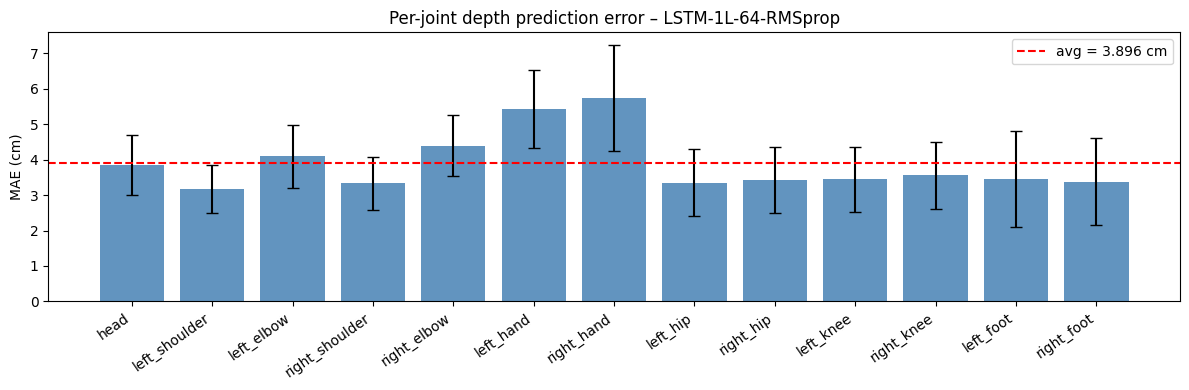

In [18]:
mae_map       = dict(variant_results)
champion_arr  = mae_map[best_label]
m_j = np.mean(champion_arr, axis=0) * 100
s_j = np.std(champion_arr,  axis=0) * 100

print(f'Champion: {best_label}')
print(f'  {"Joint":20s}  {"mean (cm)":>10}  {"std (cm)":>10}')
print('  ' + '-' * 44)
for j, name in enumerate(JOINT_NAMES):
    print(f'  {name:20s}  {m_j[j]:10.3f}  {s_j[j]:10.3f}')
print('  ' + '-' * 44)
print(f'  {"Average":20s}  {m_j.mean():10.3f} cm')

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(JOINT_NAMES, m_j, yerr=s_j, capsize=4, color='steelblue', alpha=0.85)
ax.axhline(m_j.mean(), color='red', linestyle='--',
           label=f'avg = {m_j.mean():.3f} cm')
ax.set_xticklabels(JOINT_NAMES, rotation=35, ha='right')
ax.set_ylabel('MAE (cm)')
ax.set_title(f'Per-joint depth prediction error – {best_label}')
ax.legend()
plt.tight_layout()
plt.show()

---
## Save Champion Model (retrained on all data)

In [19]:
cfg_map = {
    'LSTM-1L-64-Adam':    (LSTMModel, dict(hidden_size=64,  n_layers=1), 'adam'),
    'LSTM-2L-64-Adam':    (LSTMModel, dict(hidden_size=64,  n_layers=2), 'adam'),
    'GRU-1L-64-Adam':     (GRUModel,  dict(hidden_size=64,  n_layers=1), 'adam'),
    'GRU-2L-64-Adam':     (GRUModel,  dict(hidden_size=64,  n_layers=2), 'adam'),
    'LSTM-1L-128-Adam':   (LSTMModel, dict(hidden_size=128, n_layers=1), 'adam'),
    'GRU-1L-128-Adam':    (GRUModel,  dict(hidden_size=128, n_layers=1), 'adam'),
    'LSTM-1L-64-RMSprop': (LSTMModel, dict(hidden_size=64,  n_layers=1), 'rmsprop'),
    'LSTM-1L-64-SGD':     (LSTMModel, dict(hidden_size=64,  n_layers=1), 'sgd'),
}

model_cls, model_kwargs, opt_name = cfg_map[best_label]
champion = model_cls(**model_kwargs).to(DEVICE)
optimizer = make_optimizer(champion, opt_name)

# Fit scaler on all data, then standardize
scaler_final = StandardScaler()
n_all = len(X_all)
X_all_scaled = scaler_final.fit_transform(
    X_all.reshape(-1, N_INPUT_FEATURES)
).reshape(n_all, WINDOW_SIZE, N_INPUT_FEATURES).astype('float32')

tr_loader, vl_loader = make_loaders(X_all_scaled, y_all)

best_val, wait, best_state = float('inf'), 0, None
for epoch in range(MAX_EPOCHS):
    train_one_epoch(champion, tr_loader, optimizer)
    vl = eval_loss(champion, vl_loader)
    if vl < best_val - 1e-7:
        best_val  = vl
        best_state = {k: v.cpu().clone() for k, v in champion.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f'Early stop at epoch {epoch+1}')
            break

champion.load_state_dict(best_state)

import pickle
save_path  = f'{best_label}_champion.pt'
scaler_path = f'{best_label}_scaler.pkl'
torch.save({'model_state':  champion.state_dict(),
            'model_cls':    best_label,
            'model_kwargs': model_kwargs,
            'window_size':  WINDOW_SIZE,
            'joint_names':  JOINT_NAMES}, save_path)
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler_final, f)
print(f'Saved model : {save_path}')
print(f'Saved scaler: {scaler_path}')

Early stop at epoch 33
Saved model : LSTM-1L-64-RMSprop_champion.pt
Saved scaler: LSTM-1L-64-RMSprop_scaler.pkl


---
## Hyperparameter Tuning – Champion Model

Fine-tune the best variant with a small grid over **learning rate** and **dropout**.
- **LR sweep**: RMSprop with lr ∈ {1e-4, 3e-4, 1e-3 (baseline), 3e-3}
- **Dropout sweep**: champion architecture with 2 layers and dropout ∈ {0.1, 0.2, 0.3}

In [44]:
def run_cv_tuned(model_cls, model_kwargs, lr=1e-3, label=''):
    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    all_mae = []

    for fold, (tr_idx, te_idx) in enumerate(kf.split(unique_seq_ids)):
        tr_seqs = unique_seq_ids[tr_idx]
        te_seqs = unique_seq_ids[te_idx]
        tr_mask = np.isin(seq_ids, tr_seqs)
        te_mask = np.isin(seq_ids, te_seqs)

        X_tr, y_tr = X_all[tr_mask], y_all[tr_mask]
        X_te, y_te = X_all[te_mask], y_all[te_mask]

        n_tr, n_te = len(X_tr), len(X_te)
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr.reshape(-1, N_INPUT_FEATURES)).reshape(n_tr, WINDOW_SIZE, N_INPUT_FEATURES).astype('float32')
        X_te = scaler.transform(X_te.reshape(-1, N_INPUT_FEATURES)).reshape(n_te, WINDOW_SIZE, N_INPUT_FEATURES).astype('float32')

        model = model_cls(**model_kwargs).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        tr_loader, vl_loader = make_loaders(X_tr, y_tr)

        best_val, wait, best_state = float('inf'), 0, None
        for epoch in range(MAX_EPOCHS):
            train_one_epoch(model, tr_loader, optimizer)
            vl_loss = eval_loss(model, vl_loader)
            if vl_loss < best_val - 1e-7:
                best_val = vl_loss
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                wait = 0
            else:
                wait += 1
                if wait >= PATIENCE:
                    break

        model.load_state_dict(best_state)
        y_pred = predict_np(model, X_te)
        mae_j  = np.mean(np.abs(y_pred - y_te), axis=0)
        all_mae.append(mae_j)
        print(f'  [{label}] fold {fold+1:2d}/{N_FOLDS}  test_MAE={np.mean(mae_j)*100:.3f} cm')

    return np.array(all_mae)

In [45]:
#  LR sweep (champion architecture)
# Self-contained lookup so this cell doesn't depend on cfg_map from cell 28
_cls_map = {
    'LSTM-1L-64-Adam':    (LSTMModel, dict(hidden_size=64,  n_layers=1)),
    'LSTM-2L-64-Adam':    (LSTMModel, dict(hidden_size=64,  n_layers=2)),
    'GRU-1L-64-Adam':     (GRUModel,  dict(hidden_size=64,  n_layers=1)),
    'GRU-2L-64-Adam':     (GRUModel,  dict(hidden_size=64,  n_layers=2)),
    'LSTM-1L-128-Adam':   (LSTMModel, dict(hidden_size=128, n_layers=1)),
    'GRU-1L-128-Adam':    (GRUModel,  dict(hidden_size=128, n_layers=1)),
    'LSTM-1L-64-RMSprop': (LSTMModel, dict(hidden_size=64,  n_layers=1)),
    'LSTM-1L-64-SGD':     (LSTMModel, dict(hidden_size=64,  n_layers=1)),
}
champ_cls, champ_kwargs = _cls_map[best_label]

lr_grid = [1e-4, 3e-4, 3e-3]  # 1e-3 excluded: same as baseline
lr_results = {}

for lr in lr_grid:
    lbl = f'{best_label}-lr{lr:.0e}'
    print(f'Running {lbl} ...')
    lr_results[lbl] = run_cv_tuned(champ_cls, champ_kwargs, lr=lr, label=lbl)

print('LR sweep done.')

Running LSTM-1L-64-RMSprop-lr1e-04 ...
  [LSTM-1L-64-RMSprop-lr1e-04] fold  1/18  test_MAE=4.052 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  2/18  test_MAE=3.159 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  3/18  test_MAE=2.851 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  4/18  test_MAE=3.491 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  5/18  test_MAE=5.060 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  6/18  test_MAE=4.260 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  7/18  test_MAE=4.502 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  8/18  test_MAE=3.925 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold  9/18  test_MAE=4.584 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 10/18  test_MAE=3.227 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 11/18  test_MAE=4.149 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 12/18  test_MAE=4.367 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 13/18  test_MAE=4.279 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 14/18  test_MAE=5.770 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 15/18  test_MAE=3.977 cm
  [LSTM-1L-64-RMSprop-lr1e-04] fold 16/18  tes

In [ ]:
#  Dropout sweep (champion with 2 layers so dropout is active)
dropout_grid = [0.1, 0.2, 0.3]
dropout_results = {}

# Force n_layers=2 so PyTorch actually applies inter-layer dropout
dropout_base_kwargs = {**champ_kwargs, 'n_layers': 2}

for dp in dropout_grid:
    lbl = f'{best_label}-drop{dp}'
    print(f'Running {lbl} ...')
    kwargs = {**dropout_base_kwargs, 'dropout': dp}
    dropout_results[lbl] = run_cv_tuned(champ_cls, kwargs, lr=1e-3, label=lbl)

print('Dropout sweep done.')

Running LSTM-1L-64-RMSprop-drop0.1 ...
  [LSTM-1L-64-RMSprop-drop0.1] fold  1/18  test_MAE=3.751 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  2/18  test_MAE=2.818 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  3/18  test_MAE=2.584 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  4/18  test_MAE=2.665 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  5/18  test_MAE=5.241 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  6/18  test_MAE=4.538 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  7/18  test_MAE=4.635 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  8/18  test_MAE=3.979 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold  9/18  test_MAE=4.147 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 10/18  test_MAE=3.686 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 11/18  test_MAE=4.332 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 12/18  test_MAE=4.566 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 13/18  test_MAE=4.111 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 14/18  test_MAE=6.967 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 15/18  test_MAE=2.510 cm
  [LSTM-1L-64-RMSprop-drop0.1] fold 16/18  tes

                      Variant  Avg MAE (cm)  Fold std (cm)
   LSTM-1L-64-RMSprop-lr1e-03         3.833          0.837
   LSTM-1L-64-RMSprop-drop0.2         3.856          0.823
   LSTM-1L-64-RMSprop-lr3e-03         3.878          0.916
LSTM-1L-64-RMSprop (baseline)         3.896          0.762
   LSTM-1L-64-RMSprop-drop0.3         3.903          0.955
   LSTM-1L-64-RMSprop-drop0.1         4.021          1.086
   LSTM-1L-64-RMSprop-lr1e-04         4.079          0.859
   LSTM-1L-64-RMSprop-lr3e-04         4.354          1.157


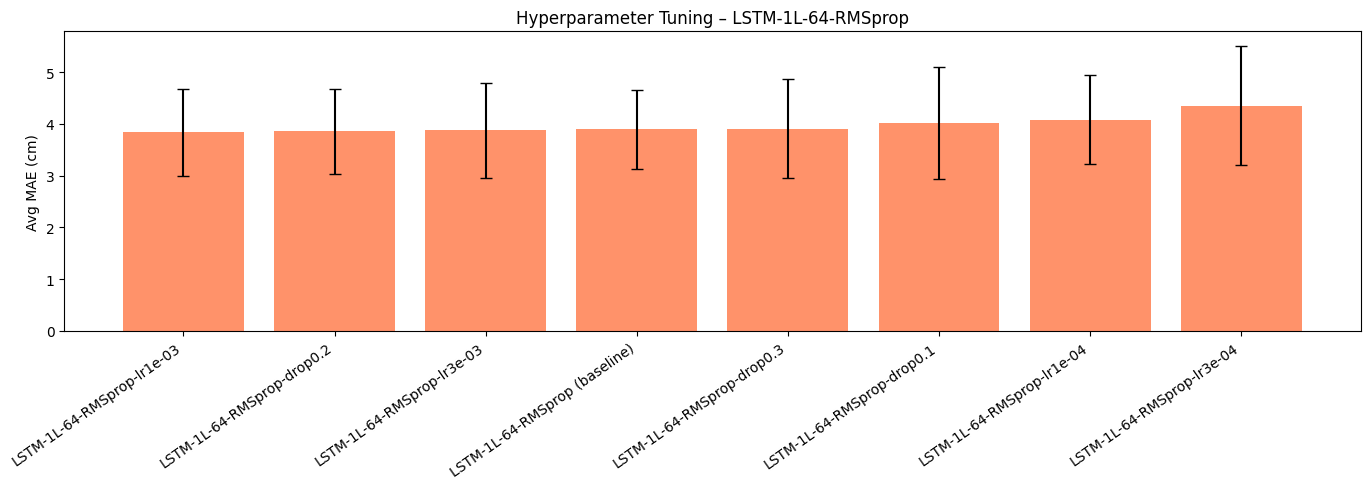

In [ ]:
# Tuning comparison table
all_tuning = {**lr_results, **dropout_results}

# Add baseline only if the 8-variant results are available
if 'mae_map' in dir():
    all_tuning[f'{best_label} (baseline)'] = mae_map[best_label]

tune_rows = []
for lbl, arr in sorted(all_tuning.items(), key=lambda x: np.mean(x[1])):
    tune_rows.append({
        'Variant':       lbl,
        'Avg MAE (cm)':  round(np.mean(arr) * 100, 3),
        'Fold std (cm)': round(np.std(np.mean(arr, axis=1)) * 100, 3),
    })

tune_df = pd.DataFrame(tune_rows)
print(tune_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(len(tune_df)), tune_df['Avg MAE (cm)'],
       yerr=tune_df['Fold std (cm)'], capsize=4, color='coral', alpha=0.85)
ax.set_xticks(range(len(tune_df)))
ax.set_xticklabels(tune_df['Variant'], rotation=35, ha='right')
ax.set_ylabel('Avg MAE (cm)')
ax.set_title(f'Hyperparameter Tuning – {best_label}')
plt.tight_layout()
plt.show()

---
## Save Best Tuned Model (retrained on all data)

In [43]:
# Set best_label manually to skip rerunning all 8 variants
if 'best_label' not in dir():
    best_label = 'LSTM-1L-64-RMSprop'
print(f'Champion: {best_label}')

Champion: LSTM-1L-64-RMSprop


In [36]:
# Best tuned variant: LSTM-1L-64 + RMSprop lr=1e-3
tuned_label  = f'{best_label}-lr1e-03'
tuned_kwargs = dict(hidden_size=64, n_layers=1)
tuned_lr     = 1e-3

print(f'Retraining {tuned_label} on all data ...')
tuned_model = LSTMModel(**tuned_kwargs).to(DEVICE)
tuned_opt   = torch.optim.RMSprop(tuned_model.parameters(), lr=tuned_lr)

import pickle
scaler_tuned = StandardScaler()
n_all = len(X_all)
X_all_scaled = scaler_tuned.fit_transform(
    X_all.reshape(-1, N_INPUT_FEATURES)
).reshape(n_all, WINDOW_SIZE, N_INPUT_FEATURES).astype('float32')

tr_loader, vl_loader = make_loaders(X_all_scaled, y_all)

best_val, wait, best_state = float('inf'), 0, None
for epoch in range(MAX_EPOCHS):
    train_one_epoch(tuned_model, tr_loader, tuned_opt)
    vl = eval_loss(tuned_model, vl_loader)
    if vl < best_val - 1e-7:
        best_val   = vl
        best_state = {k: v.cpu().clone() for k, v in tuned_model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f'Early stop at epoch {epoch+1}')
            break

tuned_model.load_state_dict(best_state)

save_path   = f'{tuned_label}_champion.pt'
scaler_path = f'{tuned_label}_scaler.pkl'
torch.save({'model_state':  tuned_model.state_dict(),
            'model_cls':    tuned_label,
            'model_kwargs': tuned_kwargs,
            'window_size':  WINDOW_SIZE,
            'joint_names':  JOINT_NAMES}, save_path)
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler_tuned, f)

print(f'Saved model : {save_path}')
print(f'Saved scaler: {scaler_path}')

Retraining LSTM-1L-64-RMSprop-lr1e-03 on all data ...
Early stop at epoch 39
Saved model : LSTM-1L-64-RMSprop-lr1e-03_champion.pt
Saved scaler: LSTM-1L-64-RMSprop-lr1e-03_scaler.pkl
